# RQ4 — HQCM-Adapted Paired Comparison

This notebook reproduces the project-level paired analysis for the supplementary adapted comparison between **GPT-OSS 20B (ours)** and **CodeFuse HQCM**.

The frozen benchmark contains **30 projects** and is based on the adapted **8-class** cohort containing **2,132 commits**. Projects are the paired experimental units, so inference is performed on

$$
\Delta = \mathrm{MacroF1}_{\mathrm{GPT\text{-}OSS}}
         - \mathrm{MacroF1}_{\mathrm{CodeFuse\ HQCM}}.
$$

Positive values favor GPT-OSS and negative values favor CodeFuse HQCM. Because this notebook contains one prespecified pairwise comparison, no multiple-comparison correction is applied.

The test is selected from the paired differences:

- paired Student's $t$-test with Hedges' $g$ when Shapiro--Wilk does not reject normality of $\Delta$;
- Wilcoxon signed-rank test with matched-pairs rank-biserial correlation ($r_{rb}$) otherwise.

The input is a frozen project-level metric table from `../metrics/benchmark_macro_f1.csv`. Missing or unexpected project rows cause the notebook to fail rather than silently changing the paired cohort.


In [9]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

try:
    import pingouin as pg
except ImportError as exc:
    raise ImportError(
        "This notebook requires 'pingouin'. Install the replication-package "
        "dependencies from requirements.txt before running the analysis."
    ) from exc

DATA_FILENAME = "benchmark_macro_f1.csv"
EXPECTED_PROJECTS = 30
EXPECTED_COLUMNS = ['project', 'gpt-oss', 'hqcm', 'delta_gpt_minus_hqcm']
MODEL_COLUMNS = ["gpt-oss", "hqcm"]
DELTA_COLUMN = "delta_gpt_minus_hqcm"

DISPLAY_LABELS = {
    "gpt-oss": "GPT-OSS 20B (ours)",
    "hqcm": "CodeFuse HQCM",
}


def locate_benchmark_file(filename=DATA_FILENAME):
    """Locate the frozen adapted benchmark from the notebook folder or repo root."""
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / ".." / "metrics" / filename,
        cwd / "metrics" / filename,
        cwd / "results" / "rq4_2" / "related_work_artifacts" / "hqcm" / "metrics" / filename,
    ]

    for parent in (cwd, *cwd.parents):
        candidates.append(
            parent / "results" / "rq4_2" / "related_work_artifacts" / "hqcm" / "metrics" / filename
        )

    seen = []
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.append(candidate)
        if candidate.is_file():
            return candidate

    checked = "\n".join(f"  - {path}" for path in seen)
    raise FileNotFoundError(
        f"Could not locate {filename}. Checked:\n{checked}"
    )


DATA_PATH = locate_benchmark_file()

df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()

missing_columns = [c for c in EXPECTED_COLUMNS if c not in df_raw.columns]
extra_columns = [c for c in df_raw.columns if c not in EXPECTED_COLUMNS]
if missing_columns or extra_columns:
    raise ValueError(
        "Unexpected benchmark schema. "
        f"Missing={missing_columns}; extra={extra_columns}."
    )

if len(df_raw) != EXPECTED_PROJECTS:
    raise ValueError(
        f"Expected {EXPECTED_PROJECTS} project rows, found {len(df_raw)}."
    )

if df_raw["project"].isna().any() or (df_raw["project"].astype(str).str.strip() == "").any():
    raise ValueError("Project identifiers must be non-empty.")

if df_raw["project"].duplicated().any():
    duplicates = df_raw.loc[df_raw["project"].duplicated(), "project"].astype(str).tolist()
    raise ValueError(f"Duplicate project identifiers were found: {duplicates}")

for column in [*MODEL_COLUMNS, DELTA_COLUMN]:
    df_raw[column] = pd.to_numeric(df_raw[column], errors="raise")

if df_raw[[*MODEL_COLUMNS, DELTA_COLUMN]].isna().any().any():
    raise ValueError(
        "The adapted benchmark must contain complete paired scores for all 30 projects."
    )

invalid_mask = (df_raw[MODEL_COLUMNS] < 0) | (df_raw[MODEL_COLUMNS] > 1)
if invalid_mask.any().any():
    raise ValueError("Macro-F1 values must lie in the [0, 1] interval.")

computed_delta = df_raw["gpt-oss"] - df_raw["hqcm"]
if not np.allclose(
    computed_delta.to_numpy(),
    df_raw[DELTA_COLUMN].to_numpy(),
    rtol=0.0,
    atol=1e-12,
):
    raise ValueError(
        f"{DELTA_COLUMN} is inconsistent with gpt-oss - hqcm."
    )

paired_data = (
    df_raw.set_index("project")[MODEL_COLUMNS]
    .rename(columns=DISPLAY_LABELS)
    .copy()
)
MODEL_A, MODEL_B = paired_data.columns.tolist()

print(f"Benchmark file: {DATA_PATH}")
print(f"Complete paired projects: {len(paired_data)}")
print(f"Comparison: {MODEL_A} − {MODEL_B}")
display(paired_data.head())


Benchmark file: D:\sources\next.release.number\results\rq4_2\related_work_artifacts\hqcm\metrics\benchmark_macro_f1.csv
Complete paired projects: 30
Comparison: GPT-OSS 20B (ours) − CodeFuse HQCM


,GPT-OSS 20B (ours),CodeFuse HQCM
project,,
angular,0.473419,0.387503
ant-design,0.502474,0.488262
biome,0.654113,0.445990
bun,0.678788,0.546860
clap,0.711670,0.477778


## Automatic paired analysis

Normality is assessed on the paired differences, not on the two model distributions separately. The parametric route reports an unadjusted 95% confidence interval for the mean paired difference. A non-significant test does not establish equivalence between the methods.


In [10]:
import textwrap
from scipy.stats import shapiro, t, ttest_rel


def _format_decimal(value, digits=3):
    text = f"{float(value):.{digits}f}"
    if text.startswith("0."):
        return text[1:]
    if text.startswith("-0."):
        return "-" + text[2:]
    return text


def _format_p_markdown(p_value):
    p_value = float(p_value)
    if p_value < 0.001:
        return r"$p<.001$"
    return f"$p={_format_decimal(p_value)}$"


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _pingouin_value(row, *candidates):
    normalized = {
        str(column).lower().replace("-", "_"): column
        for column in row.index
    }
    for candidate in candidates:
        key = candidate.lower().replace("-", "_")
        if key in normalized:
            return row[normalized[key]]
    raise KeyError(
        f"None of these columns were found: {candidates}"
    )


def _effect_magnitude(effect, route):
    value = abs(float(effect))
    if route == "parametric":
        if value < 0.2:
            return "Negligible"
        if value < 0.5:
            return "Small"
        if value < 0.8:
            return "Medium"
        return "Large"

    if value < 0.1:
        return "Negligible"
    if value < 0.3:
        return "Small"
    if value < 0.5:
        return "Medium"
    return "Large"


def run_hqcm_comparison(
    data,
    model_a,
    model_b,
    alpha=0.05,
):
    values_a = data[model_a]
    values_b = data[model_b]
    differences = values_a - values_b
    n = len(differences)

    shapiro_statistic, shapiro_p = shapiro(differences)
    route = (
        "parametric"
        if shapiro_p >= alpha
        else "non-parametric"
    )

    model_summary = pd.DataFrame({
        "N": [n, n],
        "Mean Macro-F1": [values_a.mean(), values_b.mean()],
        "SD": [values_a.std(ddof=1), values_b.std(ddof=1)],
        "Median": [values_a.median(), values_b.median()],
        "Minimum": [values_a.min(), values_b.min()],
        "Maximum": [values_a.max(), values_b.max()],
    }, index=[model_a, model_b])
    model_summary.index.name = "Model"

    mean_difference = differences.mean()
    sd_difference = differences.std(ddof=1)

    if route == "parametric":
        statistic, p_value = ttest_rel(values_a, values_b)
        standard_error = differences.sem()
        critical_t = t.ppf(0.975, df=n - 1)
        ci_lower = mean_difference - critical_t * standard_error
        ci_upper = mean_difference + critical_t * standard_error

        if np.allclose(differences, 0):
            effect = 0.0
        else:
            effect = pg.compute_effsize(
                values_a.to_numpy(),
                values_b.to_numpy(),
                paired=True,
                eftype="hedges",
            )

        statistic_name = "t"
        degrees_freedom = n - 1
        effect_name = "Hedges' g"
    else:
        if np.allclose(differences, 0):
            statistic = 0.0
            p_value = 1.0
            effect = 0.0
        else:
            wilcoxon = pg.wilcoxon(
                values_a.to_numpy(),
                values_b.to_numpy(),
                alternative="two-sided",
            ).iloc[0]
            statistic = _pingouin_value(
                wilcoxon,
                "W_val",
                "W-val",
            )
            p_value = _pingouin_value(
                wilcoxon,
                "p_val",
                "p-val",
            )
            effect = _pingouin_value(wilcoxon, "RBC")

        ci_lower = np.nan
        ci_upper = np.nan
        statistic_name = "W"
        degrees_freedom = np.nan
        effect_name = "Rank-biserial correlation"

    comparison = {
        "Comparison": f"{model_a} − {model_b}",
        "N": n,
        "Mean Difference": mean_difference,
        "SD Difference": sd_difference,
        "CI95 Lower": ci_lower,
        "CI95 Upper": ci_upper,
        "Statistic name": statistic_name,
        "Statistic": float(statistic),
        "df": degrees_freedom,
        "p": float(p_value),
        "Effect name": effect_name,
        "Effect": float(effect),
        "Effect magnitude": _effect_magnitude(effect, route),
        "Significant": bool(p_value < alpha),
    }

    direction = pd.DataFrame([{
        f"{model_a} higher": int((differences > 0).sum()),
        f"{model_b} higher": int((differences < 0).sum()),
        "Ties": int((differences == 0).sum()),
        "Total projects": n,
    }])

    project_results = data[[model_a, model_b]].copy()
    project_results["Difference"] = differences
    project_results["Higher model"] = np.where(
        differences > 0,
        model_a,
        np.where(differences < 0, model_b, "Tie"),
    )
    project_results = project_results.sort_values(
        "Difference",
        ascending=False,
    )

    print("DESCRIPTIVE MODEL TABLE")
    display(model_summary.round(4))
    print("SHAPIRO-WILK TEST ON PAIRED DIFFERENCES")
    display(pd.DataFrame([{
        "Comparison": f"{model_a} − {model_b}",
        "N": n,
        "W": round(shapiro_statistic, 4),
        "p": _format_p_plain(shapiro_p),
        "Normality not rejected": bool(shapiro_p >= alpha),
    }]))
    print(f"SELECTED ROUTE: {route}")
    print("PAIRED COMPARISON")
    display(pd.DataFrame([comparison]).round(4))
    print("PROJECT-LEVEL DIRECTION")
    display(direction)

    return {
        "data": data,
        "model_a": model_a,
        "model_b": model_b,
        "differences": differences,
        "model_summary": model_summary,
        "shapiro_W": float(shapiro_statistic),
        "shapiro_p": float(shapiro_p),
        "route": route,
        "comparison": comparison,
        "direction": direction,
        "project_results": project_results,
        "alpha": alpha,
    }


def generate_hqcm_report(
    analysis,
    title="RQ4 CodeFuse HQCM comparison generated from current data",
):
    model_a = analysis["model_a"]
    model_b = analysis["model_b"]
    summary = analysis["model_summary"]
    comparison = analysis["comparison"]
    route = analysis["route"]
    direction = analysis["direction"].iloc[0]

    descriptive_text = (
        f"**{model_a}** achieved a mean project Macro-F1 of "
        f"{summary.loc[model_a, 'Mean Macro-F1']:.3f}, compared "
        f"with {summary.loc[model_b, 'Mean Macro-F1']:.3f} for "
        f"**{model_b}**. The mean paired difference was "
        f"{comparison['Mean Difference']:.3f}. {model_a} was higher "
        f"in {int(direction[f'{model_a} higher'])} projects and "
        f"{model_b} was higher in "
        f"{int(direction[f'{model_b} higher'])} projects."
    )

    assumption_text = (
        "Shapiro–Wilk "
        + ("did not reject" if route == "parametric" else "rejected")
        + " normality of the paired differences "
        + f"($W={_format_decimal(analysis['shapiro_W'])}$, "
        + f"{_format_p_markdown(analysis['shapiro_p'])})."
    )

    if route == "parametric":
        inference_text = (
            "The paired Student's $t$-test "
            + ("detected" if comparison["Significant"] else "did not detect")
            + " a difference, "
            + f"$t({int(comparison['df'])})="
            + f"{comparison['Statistic']:.2f}$, "
            + f"{_format_p_markdown(comparison['p'])}, "
            + f"Hedges' $g={_format_decimal(comparison['Effect'])}$. "
            + "The unadjusted 95% confidence interval for the mean "
            + f"difference was [{comparison['CI95 Lower']:.3f}, "
            + f"{comparison['CI95 Upper']:.3f}]."
        )
    else:
        inference_text = (
            "The Wilcoxon signed-rank test "
            + ("detected" if comparison["Significant"] else "did not detect")
            + " a difference, "
            + f"$W={comparison['Statistic']:.2f}$, "
            + f"{_format_p_markdown(comparison['p'])}, "
            + f"$r_{{rb}}={_format_decimal(comparison['Effect'])}$."
        )

    if comparison["Significant"]:
        better = (
            model_a
            if comparison["Mean Difference"] > 0
            else model_b
        )
        conclusion = (
            f"**{better}** achieved significantly higher project-level "
            "Macro-F1 under this shared evaluation protocol."
        )
    else:
        conclusion = (
            "We found no statistical evidence of a project-level "
            "Macro-F1 difference between the two methods under this "
            "shared evaluation protocol. This does not establish "
            "equivalence."
        )

    report = f"""
## {title}

### Descriptive results

{descriptive_text}

### Paired inference

{assumption_text} {inference_text} No multiple-comparison correction was applied because this notebook contains one prespecified contrast.

### Data-driven interpretation

{conclusion}
"""
    return textwrap.dedent(report)


## Execute the comparison

All statistics and interpretive statements below are generated from the current paired data.


In [11]:
hqcm_analysis = run_hqcm_comparison(
    data=paired_data,
    model_a=MODEL_A,
    model_b=MODEL_B,
)
hqcm_report = generate_hqcm_report(hqcm_analysis)
display(Markdown(hqcm_report))


DESCRIPTIVE MODEL TABLE


,N,Mean Macro-F1,SD,Median,Minimum,Maximum
Model,,,,,,
GPT-OSS 20B (ours),30,0.6023,0.1425,0.6302,0.3067,0.9291
CodeFuse HQCM,30,0.4865,0.1038,0.4723,0.2918,0.6612


SHAPIRO-WILK TEST ON PAIRED DIFFERENCES


,Comparison,N,W,p,Normality not rejected
0,GPT-OSS 20B (ours) − CodeFuse HQCM,30,0.9445,.1202,True


SELECTED ROUTE: parametric
PAIRED COMPARISON


,Comparison,N,Mean Difference,SD Difference,CI95 Lower,CI95 Upper,Statistic name,Statistic,df,p,Effect name,Effect,Effect magnitude,Significant
0,GPT-OSS 20B (ours) − CodeFuse HQCM,30,0.1158,0.1249,0.0691,0.1624,t,5.0753,29,0.0,Hedges' g,0.9168,Large,True


PROJECT-LEVEL DIRECTION


,GPT-OSS 20B (ours) higher,CodeFuse HQCM higher,Ties,Total projects
0,27,3,0,30



## RQ4 CodeFuse HQCM comparison generated from current data

### Descriptive results

**GPT-OSS 20B (ours)** achieved a mean project Macro-F1 of 0.602, compared with 0.486 for **CodeFuse HQCM**. The mean paired difference was 0.116. GPT-OSS 20B (ours) was higher in 27 projects and CodeFuse HQCM was higher in 3 projects.

### Paired inference

Shapiro–Wilk did not reject normality of the paired differences ($W=.944$, $p=.120$). The paired Student's $t$-test detected a difference, $t(29)=5.08$, $p<.001$, Hedges' $g=.917$. The unadjusted 95% confidence interval for the mean difference was [0.069, 0.162]. No multiple-comparison correction was applied because this notebook contains one prespecified contrast.

### Data-driven interpretation

**GPT-OSS 20B (ours)** achieved significantly higher project-level Macro-F1 under this shared evaluation protocol.


## Project-level paired differences

Points show project-level differences, ordered from the largest GPT-OSS 20B (ours) advantage to the largest CodeFuse HQCM advantage. The dashed line represents equal Macro-F1. The mean and its unadjusted 95% confidence interval are shown when the parametric route is selected.


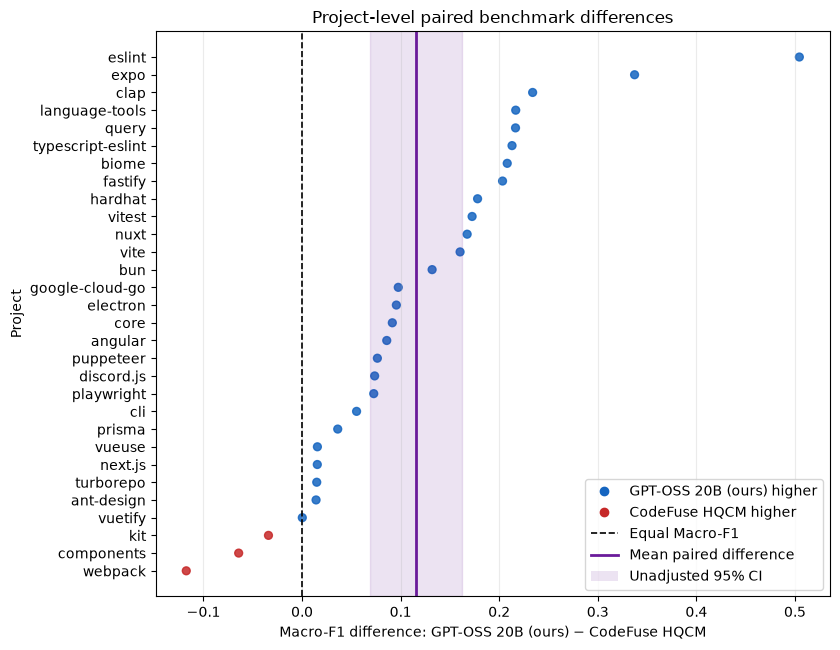

In [12]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

project_results = hqcm_analysis["project_results"].copy()
project_results = project_results.sort_values(
    "Difference",
    ascending=True,
)

figure_height = max(6, 0.22 * len(project_results))
fig, ax = plt.subplots(figsize=(8.5, figure_height))
ax.grid(True, axis="x", alpha=0.25)

colors = np.where(
    project_results["Difference"] >= 0,
    "#1565C0",
    "#C62828",
)
ax.scatter(
    project_results["Difference"],
    project_results.index.astype(str),
    c=colors,
    s=32,
    alpha=0.85,
)
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Equal Macro-F1",
)

comparison = hqcm_analysis["comparison"]
ax.axvline(
    comparison["Mean Difference"],
    color="#6A1B9A",
    linewidth=2,
    label="Mean paired difference",
)

if hqcm_analysis["route"] == "parametric":
    ax.axvspan(
        comparison["CI95 Lower"],
        comparison["CI95 Upper"],
        color="#6A1B9A",
        alpha=0.12,
        label="Unadjusted 95% CI",
    )

ax.set_xlabel(f"Macro-F1 difference: {MODEL_A} − {MODEL_B}")
ax.set_ylabel("Project")
ax.set_title("Project-level paired benchmark differences")
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#1565C0",
        markeredgecolor="#1565C0",
        label=f"{MODEL_A} higher",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#C62828",
        markeredgecolor="#C62828",
        label=f"{MODEL_B} higher",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="--",
        linewidth=1.2,
        label="Equal Macro-F1",
    ),
    Line2D(
        [0],
        [0],
        color="#6A1B9A",
        linewidth=2,
        label="Mean paired difference",
    ),
]
if hqcm_analysis["route"] == "parametric":
    legend_handles.append(
        Patch(
            facecolor="#6A1B9A",
            alpha=0.12,
            label="Unadjusted 95% CI",
        )
    )
ax.legend(handles=legend_handles, frameon=True, loc="best")
fig.tight_layout()
plt.show()


## Reproducibility notes

- The notebook reads only the frozen local metric table in `../metrics/benchmark_macro_f1.csv` (or the equivalent path when launched from the repository root).
- Exactly 30 unique project rows and the expected schema are required; missing projects or scores cause an error rather than complete-case filtering.
- The stored delta column is validated against `gpt-oss - hqcm` before analysis.
- Normality is tested on the paired project-level differences.
- One prespecified comparison does not require Holm or Bonferroni correction.
- Hedges' $g$ is reported on the parametric route; matched-pairs rank-biserial correlation is reported on the Wilcoxon route.
- A non-significant difference is not evidence of equivalence.
- The model summary, paired comparison, and project direction counts are displayed inline above; the frozen input remains under `metrics/` and nothing is written back to `results/`.
